Credit: This code is adapted from the Keras example [DreamBooth](https://keras.io/examples/generative/dreambooth/).

### Changes from the original example

- **Class images:** generated with SD3 from `class_prompt` (200 images, saved to `class-images/`, and re-runs skip the ones already on disk) instead of downloading a pre-made set. Prior preservation only works when the class images come from the model being fine-tuned.
- **Mixed precision:** the policy is now set before SD3 is built (before, its layers stayed in float32), and it uses `mixed_bfloat16` instead of `mixed_float16`, which doesn't need loss scaling.
- **One SD3 instance:** SD3 is loaded once and reused for class-image generation, prompt encoding, training and inference. Inference no longer loads a second float32 copy, and the trainer and optimizer are deleted first to free memory.
- **Prompt embeddings:** one float32 NumPy copy per prompt, repeated per batch inside the dataset, instead of hundreds of pre-repeated copies.
- **Image loading:** images are center-cropped to a square before resizing (`keep_aspect_ratio=True`) so the subject keeps its proportions instead of being squashed. Flips are horizontal only; the original also flipped images upside down.
- **Noise sampling:** noise levels are drawn logit-normal with SD3's shift, the way SD3 was trained, instead of uniformly, and are passed to the diffuser on the scheduler's timestep scale (`sigma * num_train_timesteps`) instead of as raw 0–1 values. Random ops use a `SeedGenerator` so the train step also works on JAX.
- **Optimizer:** `global_clipnorm=1.0` clips the total gradient norm, as the Diffusers script does, instead of clipping each variable separately.
- **Training length:** `max_train_steps` lowered from 1200 to 800.
- **Cleanup:** the dataset takes `resolution` as an argument instead of reading a global, the instance images are cycled inside the dataset, and unused trainer arguments (`use_mixed_precision`, `max_grad_norm`) and the checkpoint callback's unused `monitor`/`mode` settings were removed.


<br>
## Initial imports<br>
Install the dependencies first, then restart the runtime so the freshly installed<br>
versions are the ones that get imported.<br>


In [ ]:
%pip install --upgrade keras keras-hub imutils opencv-python

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 72.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 97.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.0/230.0 kB 26.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 50.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 MB 28.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 64.7 MB/s eta 0:00:00
  Created wheel for imutils: filename=imutils-0.5.4-py3-none-any.whl size=25870 sha256=ba3b00de2c1ff7a76a8ce9fc06f2a4acfbeff03110e53f20730c21dc7787f030
  Stored in directory: /root/.cache/pip/wheels/69/2c/66/f966db29490794305257ac3abfe

In [ ]:
import gc
import os
import math
import keras
import keras_hub
import matplotlib.pyplot as plt
import numpy as np
from imutils import paths

/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:86: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(



<br>
## Usage of DreamBooth<br>
... is very versatile. By teaching Stable Diffusion about your favorite visual<br>
concepts, you can<br>
* Recontextualize objects in interesting ways:<br>
  ![](https://i.imgur.com/4Da9ozw.png)<br>
* Generate artistic renderings of the underlying visual concept:<br>
  ![](https://i.imgur.com/nI2N8bI.png)<br>
And many other applications. We welcome you to check out the original<br>
[DreamBooth paper](https://arxiv.org/abs/2208.12242) in this regard.<br>


In [ ]:
instance_images_root = keras.utils.get_file(
    origin="https://huggingface.co/datasets/sayakpaul/sample-datasets/resolve/main/instance-images.tar.gz",
    untar=True,
)

5556967/5556967 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step   



<br>
## Visualize images<br>
First, let's load the instance image paths. The class images are generated with<br>
Stable Diffusion 3 further below.<br>


In [ ]:
instance_image_paths = list(paths.list_images(instance_images_root))


<br>
Then we load the images from the paths.<br>


In [ ]:
def load_images(image_paths):
    images = [np.array(keras.utils.load_img(path)) for path in image_paths]
    return images


<br>
And then we make use a utility function to plot the loaded images.<br>


In [ ]:
def plot_images(images, title=None):
    plt.figure(figsize=(20, 20))
    for i in range(len(images)):
        ax = plt.subplot(1, len(images), i + 1)
        if title is not None:
            plt.title(title)
        plt.imshow(images[i])
        plt.axis("off")


<br>
**Instance images**:<br>


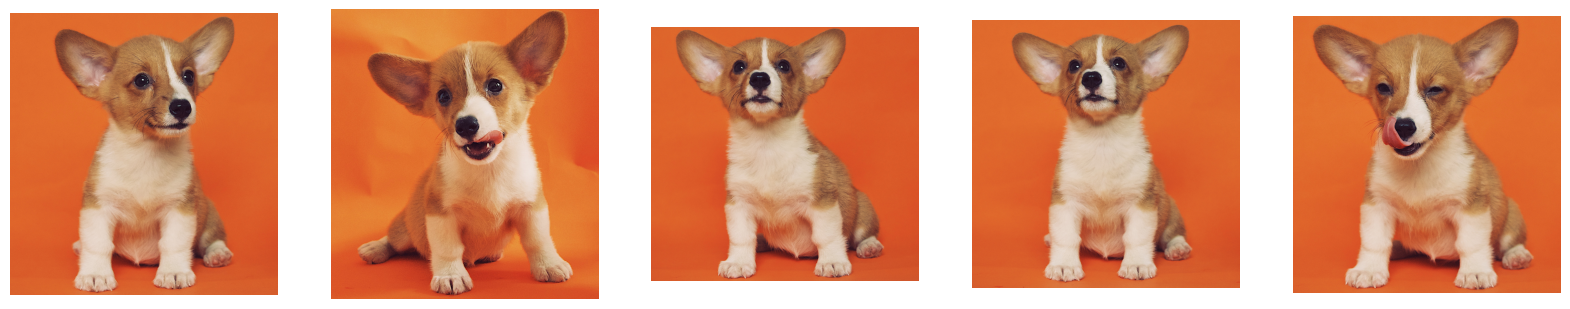

In [ ]:
plot_images(load_images(instance_image_paths[:5]))


<br>
## Prepare datasets<br>
Dataset preparation includes two stages: (1): preparing the captions, (2) processing the<br>
images.<br>



<br>
### Prepare the captions<br>


In [ ]:
unique_id = "sks"
class_label = "dog"

In [ ]:
instance_prompt = f"a photo of {unique_id} {class_label}"
class_prompt = f"a photo of {class_label}"


<br>
### Load Stable Diffusion 3<br>
We load SD3 once and reuse it to generate the class images, embed the prompts, train,<br>
and run inference. The precision policy has to be set before the model is built,<br>
otherwise its layers stay in float32. `mixed_bfloat16` runs on TPUs and recent GPUs<br>
and doesn't need loss scaling.<br>


In [ ]:
use_mp = True
if use_mp:
    keras.mixed_precision.set_global_policy("mixed_bfloat16")

In [ ]:
print("Loading Stable Diffusion 3 (reused for every step below)...")
sd3_backbone = keras_hub.models.StableDiffusion3Backbone.from_preset(
    "stable_diffusion_3_medium",
    image_shape=(512, 512, 3),
)
sd3_preprocessor = keras_hub.models.StableDiffusion3TextToImagePreprocessor.from_preset(
    "stable_diffusion_3_medium"
)

Loading Stable Diffusion 3 (reused for every step below)...


100%|██████████| 4.19k/4.19k [00:00<00:00, 14.1MB/s]


100%|██████████| 5.57G/5.57G [03:08<00:00, 31.7MB/s]


100%|██████████| 4.08k/4.08k [00:00<00:00, 13.8MB/s]


100%|██████████| 976k/976k [00:00<00:00, 1.69MB/s]


100%|██████████| 512k/512k [00:00<00:00, 1.05MB/s]


100%|██████████| 976k/976k [00:00<00:00, 1.55MB/s]


100%|██████████| 512k/512k [00:00<00:00, 1.09MB/s]



<br>
### Generate the class images<br>
Prior preservation keeps the model's own idea of the class (here, "dog") from drifting<br>
while it learns the new subject. For that to work, the class images have to come from<br>
the model being fine-tuned, so we generate them with SD3 from `class_prompt`. This<br>
takes a while. The images are written to disk, and re-running the cell skips the ones<br>
that already exist.<br>


In [ ]:
num_class_images = 200
class_images_root = "class-images"
os.makedirs(class_images_root, exist_ok=True)
num_existing = len(list(paths.list_images(class_images_root)))
if num_existing < num_class_images:
    class_image_generator = keras_hub.models.StableDiffusion3TextToImage(
        backbone=sd3_backbone, preprocessor=sd3_preprocessor
    )
    generation_batch_size = 4
    for start in range(num_existing, num_class_images, generation_batch_size):
        count = min(generation_batch_size, num_class_images - start)
        images = class_image_generator.generate([class_prompt] * count, seed=start)
        for offset, image in enumerate(images):
            keras.utils.save_img(
                os.path.join(class_images_root, f"{start + offset:04d}.png"),
                image,
                scale=False,
            )
    del class_image_generator

In [ ]:
class_image_paths = list(paths.list_images(class_images_root))


<br>
**Class images**:<br>


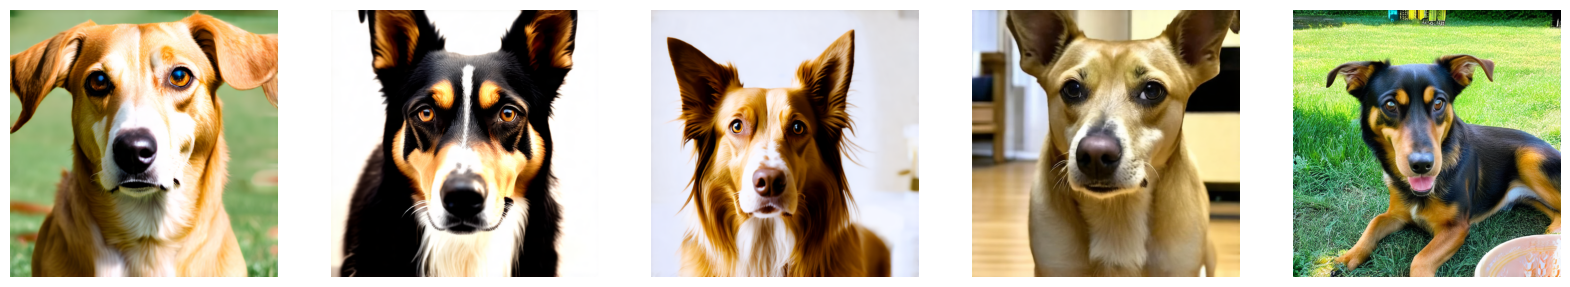

In [ ]:
plot_images(load_images(class_image_paths[:5]))


<br>
Next, we embed the prompts to save some compute.<br>


In [ ]:
unique_prompts = [instance_prompt, class_prompt]
print(
    f"Encoding {len(unique_prompts)} unique prompts (instead of {2 * len(class_image_paths)})..."
)

In [ ]:
token_ids = sd3_preprocessor.generate_preprocess(unique_prompts)
negative_token_ids = sd3_preprocessor.generate_preprocess(["", ""])

In [ ]:
(
    positive_embeddings,
    _,
    positive_pooled,
    _,
) = sd3_backbone.encode_text_step(token_ids, negative_token_ids)


<br>
Each prompt only has one embedding, so we keep a single copy of each and let the<br>
dataset repeat it per batch. Converting to NumPy here also keeps the dataset<br>
independent of the backend's device tensors.<br>


In [ ]:
def to_numpy(embedding):
    return keras.ops.convert_to_numpy(keras.ops.cast(embedding, "float32"))

In [ ]:
positive_embeddings = to_numpy(positive_embeddings)
positive_pooled = to_numpy(positive_pooled)
instance_embedding = positive_embeddings[0]
class_embedding = positive_embeddings[1]
instance_pooled = positive_pooled[0]
class_pooled = positive_pooled[1]

In [ ]:
print(f"Text embedding shapes: {instance_embedding.shape}, {class_embedding.shape}")
print(f"Pooled embedding shapes: {instance_pooled.shape}, {class_pooled.shape}")

Text embedding shapes: (154, 4096), (154, 4096)
Pooled embedding shapes: (2048,), (2048,)



<br>
## Prepare the images<br>


In [ ]:
resolution = 512

In [ ]:
augmenter = keras.Sequential(
    layers=[
        keras.layers.RandomFlip(mode="horizontal"),
        keras.layers.Rescaling(scale=1.0 / 127.5, offset=-1),
    ]
)

In [ ]:
class DreamBoothDataset(keras.utils.PyDataset):
    """Backend-agnostic dataset for DreamBooth training.
    This dataset handles both instance and class images for prior preservation.
    Every class image is paired with an instance image, cycling through the few
    instance images, so each batch holds the same number of both.
    """
    def __init__(
        self,
        instance_image_paths,
        class_image_paths,
        instance_embedding,
        class_embedding,
        instance_pooled_embedding,
        class_pooled_embedding,
        augmenter,
        resolution,
        batch_size=1,
        shuffle=True,
        seed=420,
        **kwargs,
    ):
        super().__init__(**kwargs)
        self.instance_image_paths = instance_image_paths
        self.class_image_paths = class_image_paths
        self.instance_embedding = instance_embedding
        self.class_embedding = class_embedding
        self.instance_pooled_embedding = instance_pooled_embedding
        self.class_pooled_embedding = class_pooled_embedding
        self.augmenter = augmenter
        self.resolution = resolution
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.seed = seed
        self.rng = np.random.default_rng(seed)
        self.num_samples = len(class_image_paths)
        self.on_epoch_end()
    def __len__(self):
        return int(np.ceil(self.num_samples / self.batch_size))
    def on_epoch_end(self):
        """Shuffle indices at end of epoch if shuffle=True."""
        self.indices = np.arange(self.num_samples)
        if self.shuffle:
            self.rng.shuffle(self.indices)
    def _load_batch_images(self, image_paths, batch_indices):
        # Center-crop to a square before resizing so the subject keeps its
        # proportions.
        images = [
            keras.utils.img_to_array(
                keras.utils.load_img(
                    image_paths[index % len(image_paths)],
                    target_size=(self.resolution, self.resolution),
                    keep_aspect_ratio=True,
                )
            )
            for index in batch_indices
        ]
        return np.array(images)
    def _repeat_for_batch(self, value, batch_size):
        return np.repeat(value[np.newaxis], batch_size, axis=0)
    def __getitem__(self, idx):
        """Generate one batch of data."""
        batch_indices = self.indices[
            idx * self.batch_size : (idx + 1) * self.batch_size
        ]
        batch_size = len(batch_indices)
        instance_images = self._load_batch_images(
            self.instance_image_paths, batch_indices
        )
        class_images = self._load_batch_images(self.class_image_paths, batch_indices)
        instance_images = self.augmenter(instance_images, training=True)
        class_images = self.augmenter(class_images, training=True)
        instance_batch = {
            "instance_images": instance_images,
            "instance_embedded_texts": self._repeat_for_batch(
                self.instance_embedding, batch_size
            ),
            "instance_pooled_embeddings": self._repeat_for_batch(
                self.instance_pooled_embedding, batch_size
            ),
        }
        class_batch = {
            "class_images": class_images,
            "class_embedded_texts": self._repeat_for_batch(
                self.class_embedding, batch_size
            ),
            "class_pooled_embeddings": self._repeat_for_batch(
                self.class_pooled_embedding, batch_size
            ),
        }
        return (instance_batch, class_batch)


<br>
## Assemble dataset<br>


In [ ]:
train_dataset = DreamBoothDataset(
    instance_image_paths=instance_image_paths,
    class_image_paths=class_image_paths,
    instance_embedding=instance_embedding,
    class_embedding=class_embedding,
    instance_pooled_embedding=instance_pooled,
    class_pooled_embedding=class_pooled,
    augmenter=augmenter,
    resolution=resolution,
    batch_size=1,
    shuffle=True,
    workers=2,
    use_multiprocessing=False,
)


<br>
## Check shapes<br>
Now that the dataset has been prepared, let's quickly check what's inside it.<br>


In [ ]:
sample_batch = next(iter(train_dataset))
print(sample_batch[0].keys(), sample_batch[1].keys())

dict_keys(['instance_images', 'instance_embedded_texts', 'instance_pooled_embeddings']) dict_keys(['class_images', 'class_embedded_texts', 'class_pooled_embeddings'])


In [ ]:
for k in sample_batch[0]:
    print(k, sample_batch[0][k].shape)

instance_images (1, 512, 512, 3)
instance_embedded_texts (1, 154, 4096)
instance_pooled_embeddings (1, 2048)


In [ ]:
for k in sample_batch[1]:
    print(k, sample_batch[1][k].shape)

class_images (1, 512, 512, 3)
class_embedded_texts (1, 154, 4096)
class_pooled_embeddings (1, 2048)



<br>
During training, we make use of these keys to gather the images and text embeddings and<br>
concat them accordingly.<br>



<br>
## DreamBooth training loop<br>
Our DreamBooth training loop is very much inspired by<br>
[this script](https://github.com/huggingface/diffusers/blob/main/examples/dreambooth/train_dreambooth.py)<br>
provided by the Diffusers team at Hugging Face. However, there is an important<br>
difference to note. We only fine-tune the diffusion model (the component responsible for predicting<br>
noise / velocity) and don't fine-tune the text encoder in this example. If you're looking for an<br>
implementation that also performs the additional fine-tuning of the text encoder, refer<br>
to [this repository](https://github.com/sayakpaul/dreambooth-keras/).<br>


In [ ]:
class DreamBoothTrainer(keras.Model):
    def __init__(
        self,
        diffusion_model,
        vae,
        backbone,
        noise_scheduler,
        prior_loss_weight=1.0,
        seed=None,
        **kwargs,
    ):
        super().__init__(**kwargs)
        self.diffusion_model = diffusion_model
        self.vae = vae
        self.backbone = backbone
        self.noise_scheduler = noise_scheduler
        self.prior_loss_weight = prior_loss_weight
        # JAX only allows seeded random ops inside the traced train step.
        self.seed_generator = keras.random.SeedGenerator(seed)

        # Only the diffusion model is fine-tuned. `trainable` on the backbone
        # also applies to all of its sub-layers (the VAE and text encoders),
        # so freeze the whole backbone first, then unfreeze the diffuser.
        self.backbone.trainable = False
        self.diffusion_model.trainable = True

    def call(self, inputs):
        return inputs

    def compute_loss(self, x, y, y_pred, sample_weight):
        """Backend-agnostic loss computation override.
        The default train_step calls this method inside a gradient recording scope
        (e.g., GradientTape for TF, Autograd for Torch), so we don't need to manually
        handle gradients.
        """
        instance_batch = x
        class_batch = y

        instance_images = instance_batch["instance_images"]
        instance_embedded_text = instance_batch["instance_embedded_texts"]
        instance_pooled = instance_batch["instance_pooled_embeddings"]

        class_images = class_batch["class_images"]
        class_embedded_text = class_batch["class_embedded_texts"]
        class_pooled = class_batch["class_pooled_embeddings"]

        images = keras.ops.concatenate([instance_images, class_images], axis=0)
        embedded_texts = keras.ops.concatenate(
            [instance_embedded_text, class_embedded_text], axis=0
        )
        pooled_embeddings = keras.ops.concatenate(
            [instance_pooled, class_pooled], axis=0
        )
        batch_size = keras.ops.shape(images)[0]
        return self._compute_dreambooth_loss(
            images, embedded_texts, pooled_embeddings, batch_size
        )

    def _compute_dreambooth_loss(
        self, images, embedded_texts, pooled_embeddings, batch_size
    ):
        """Internal logic for DreamBooth loss (Flow Matching)."""
        latents = self.backbone.encode_image_step(images)
        noise = keras.random.normal(
            keras.ops.shape(latents), seed=self.seed_generator
        )
        # Sample noise levels the way SD3 was trained: logit-normal, then the
        # same shift the backbone's scheduler applies at inference.
        u = keras.ops.sigmoid(
            keras.random.normal(shape=(batch_size,), seed=self.seed_generator)
        )
        shift = self.backbone.shift
        sigmas = keras.ops.divide(
            keras.ops.multiply(shift, u),
            keras.ops.add(1.0, keras.ops.multiply(shift - 1.0, u)),
        )
        noisy_latents = keras.ops.add(
            keras.ops.multiply(
                keras.ops.subtract(1.0, keras.ops.reshape(sigmas, (-1, 1, 1, 1))),
                latents,
            ),
            keras.ops.multiply(keras.ops.reshape(sigmas, (-1, 1, 1, 1)), noise),
        )
        target = keras.ops.subtract(noise, latents)
        # The diffuser takes timesteps on the scheduler's scale
        # (sigma * num_train_timesteps), as in `backbone.denoise_step`.
        timesteps = keras.ops.multiply(sigmas, self.backbone.num_train_timesteps)

        model_pred = self.diffusion_model(
            {
                "latent": noisy_latents,
                "context": embedded_texts,
                "pooled_projection": pooled_embeddings,
                "timestep": keras.ops.reshape(timesteps, (-1, 1)),
            },
            training=True,
        )
        loss = self._compute_split_loss(target, model_pred)
        return loss

    def _compute_split_loss(self, target, model_pred):
        """Compute split loss for instance and class images."""
        model_pred, model_pred_prior = keras.ops.split(model_pred, 2, axis=0)
        target, target_prior = keras.ops.split(target, 2, axis=0)
        target = keras.ops.cast(target, "float32")
        model_pred = keras.ops.cast(model_pred, "float32")
        target_prior = keras.ops.cast(target_prior, "float32")
        model_pred_prior = keras.ops.cast(model_pred_prior, "float32")
        loss = keras.ops.mean(keras.ops.square(target - model_pred))
        prior_loss = keras.ops.mean(keras.ops.square(target_prior - model_pred_prior))
        return loss + self.prior_loss_weight * prior_loss

    def save_weights(self, filepath, overwrite=True, save_format=None, options=None):
        self.diffusion_model.save_weights(filepath=filepath)

    def load_weights(self, filepath, by_name=False, skip_mismatch=False, options=None):
        self.diffusion_model.load_weights(filepath=filepath)


<br>
## Trainer initialization<br>


In [ ]:
print("Reusing SD3 backbone from text encoding step...")

Reusing SD3 backbone from text encoding step...


In [ ]:
diffusion_model = sd3_backbone.diffuser

In [ ]:
vae = sd3_backbone.vae


<br>
## Train!<br>
We first calculate the number of epochs, we need to train for.<br>


In [ ]:
num_update_steps_per_epoch = len(train_dataset)
max_train_steps = 800
epochs = math.ceil(max_train_steps / num_update_steps_per_epoch)
print(f"Training for {epochs} epochs.")

Training for 4 epochs.



<br>
And then we start training!<br>


In [ ]:
dreambooth_trainer = DreamBoothTrainer(
    diffusion_model=sd3_backbone.diffuser,
    vae=sd3_backbone.vae,
    backbone=sd3_backbone,
    noise_scheduler=None,
    prior_loss_weight=1.0,
)

In [ ]:
learning_rate = 1e-5
optimizer = keras.optimizers.AdamW(
    learning_rate=learning_rate,
    weight_decay=0.0,
    beta_1=0.9,
    beta_2=0.999,
    epsilon=1e-08,
    global_clipnorm=1.0,
)

In [ ]:
dreambooth_trainer.compile(optimizer=optimizer, loss="mse")

In [ ]:
print("Starting training (resolution: 512x512)...")
ckpt_path = "dreambooth-unet.weights.h5"
# Saves the weights after every epoch, so the file holds the final epoch.
ckpt_callback = keras.callbacks.ModelCheckpoint(
    ckpt_path,
    save_weights_only=True,
)

Starting training (resolution: 512x512)...


In [ ]:
history = dreambooth_trainer.fit(train_dataset, epochs=epochs, callbacks=[ckpt_callback])

Epoch 1/4
200/200 ━━━━━━━━━━━━━━━━━━━━ 1901s 9s/step - loss: 0.3710
Epoch 2/4
200/200 ━━━━━━━━━━━━━━━━━━━━ 1841s 9s/step - loss: 0.3646
Epoch 3/4
200/200 ━━━━━━━━━━━━━━━━━━━━ 1837s 9s/step - loss: 0.3626
Epoch 4/4
197/200 ━━━━━━━━━━━━━━━━━━━━ 27s 9s/step - loss: 0.3587


<br>
## Experiments and inference<br>
We ran various experiments with a slightly modified version of this example. Our<br>
experiments are based on<br>
[this repository](https://github.com/sayakpaul/dreambooth-keras/) and are inspired by<br>
[this blog post](https://huggingface.co/blog/dreambooth) from Hugging Face.<br>
First, let's see how we can use the fine-tuned checkpoint for running inference.<br>


In [ ]:
import numpy as np


<br>
We reuse the fine-tuned backbone for inference instead of loading a second copy of<br>
SD3. First, we drop the trainer so its optimizer state can be freed.<br>


In [ ]:
del dreambooth_trainer, optimizer, ckpt_callback, history
gc.collect()
print("Building the text-to-image model from the fine-tuned backbone...")
dreambooth_model_512 = keras_hub.models.StableDiffusion3TextToImage(
    backbone=sd3_backbone,
    preprocessor=sd3_preprocessor,
)

In [ ]:
print(f"Loading fine-tuned weights from {ckpt_path}...")
dreambooth_model_512.backbone.diffuser.load_weights(ckpt_path)


<br>
The default number of steps for generating an image with Stable Diffusion 3<br>
is 50. Let's increase it to 100 for potentially better quality.<br>


In [ ]:
prompt = f"A photo of {unique_id} {class_label} in a bucket"
print(f"Generating images for prompt: '{prompt}'...")

In [ ]:
prompts = [prompt] * 3

In [ ]:
images_dreamboothed = dreambooth_model_512.generate(prompts, num_steps=100, seed=42)

In [ ]:
images_dreamboothed = np.array(images_dreamboothed)
if images_dreamboothed.ndim == 3:
    images_dreamboothed = np.expand_dims(images_dreamboothed, axis=0)

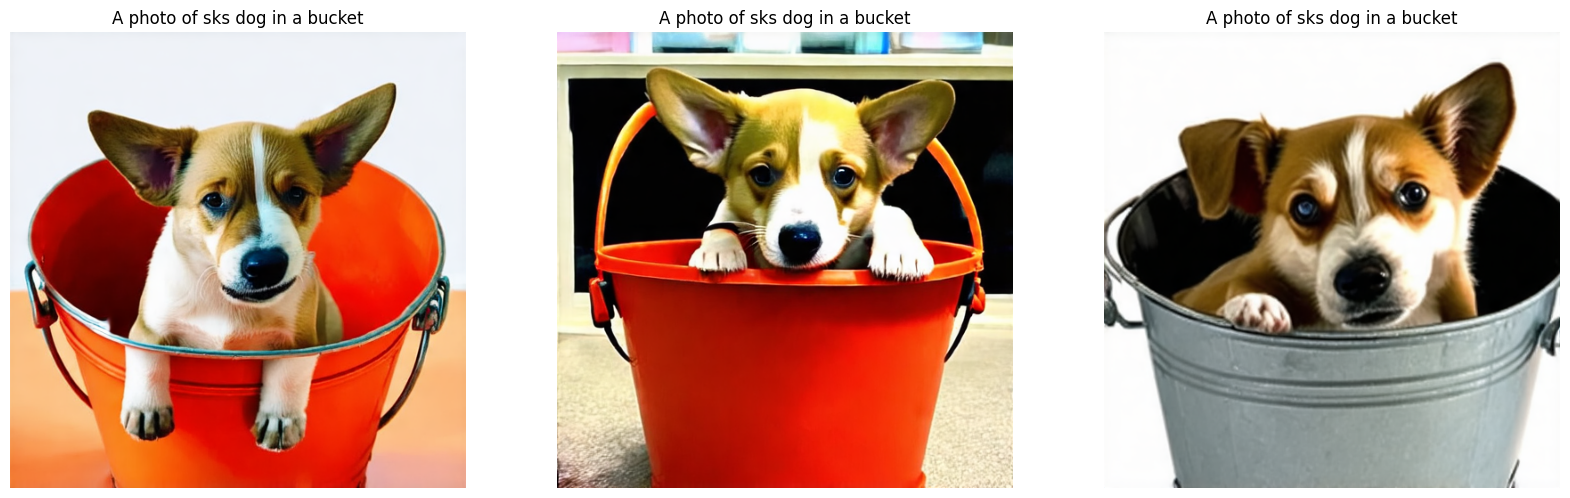

In [49]:
plot_images(images_dreamboothed, title=prompt)


<br>
Feel free to experiment with different prompts (don't forget to add the unique identifier<br>
and the class label!) to see how the results change. We welcome you to check out our<br>
codebase and more experimental results<br>
[here](https://github.com/sayakpaul/dreambooth-keras#results). You can also read<br>
[this blog post](https://huggingface.co/blog/dreambooth) to get more ideas.<br>



<br>
## Acknowledgements<br>
* Thanks to the<br>
[DreamBooth example script](https://github.com/huggingface/diffusers/blob/main/examples/dreambooth/train_dreambooth.py)<br>
provided by Hugging Face which helped us a lot in getting the initial implementation<br>
ready quickly.<br>
* Getting DreamBooth to work on human faces can be challenging. We have compiled some<br>
general recommendations<br>
[here](https://github.com/sayakpaul/dreambooth-keras#notes-on-preparing-data-for-dreambooth-training-of-faces).<br>
Thanks to<br>
[Abhishek Thakur](https://no.linkedin.com/in/abhi1thakur)<br>
for helping with these.<br>



<br>
## Relevant Chapters from Deep Learning with Python<br>
- [Chapter 17: Image generation](https://deeplearningwithpython.io/chapters/chapter17_image-generation)<br>
